<a href="https://colab.research.google.com/github/AfraazUlHaque/Non-Linear-SVM/blob/main/wine_NLSVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (1599, 12)

First 5 rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1

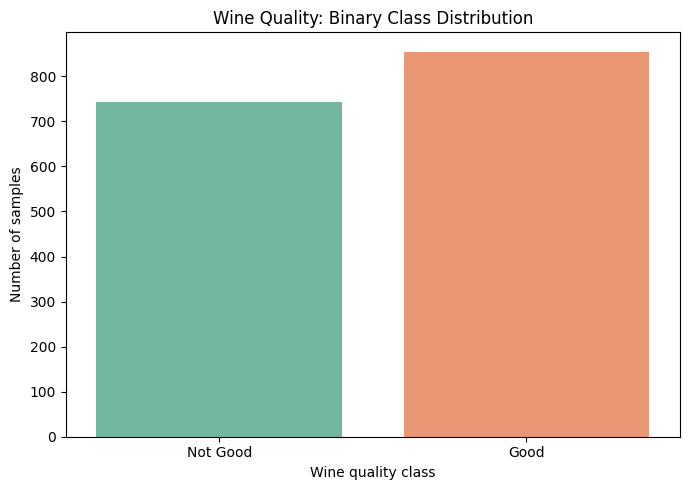

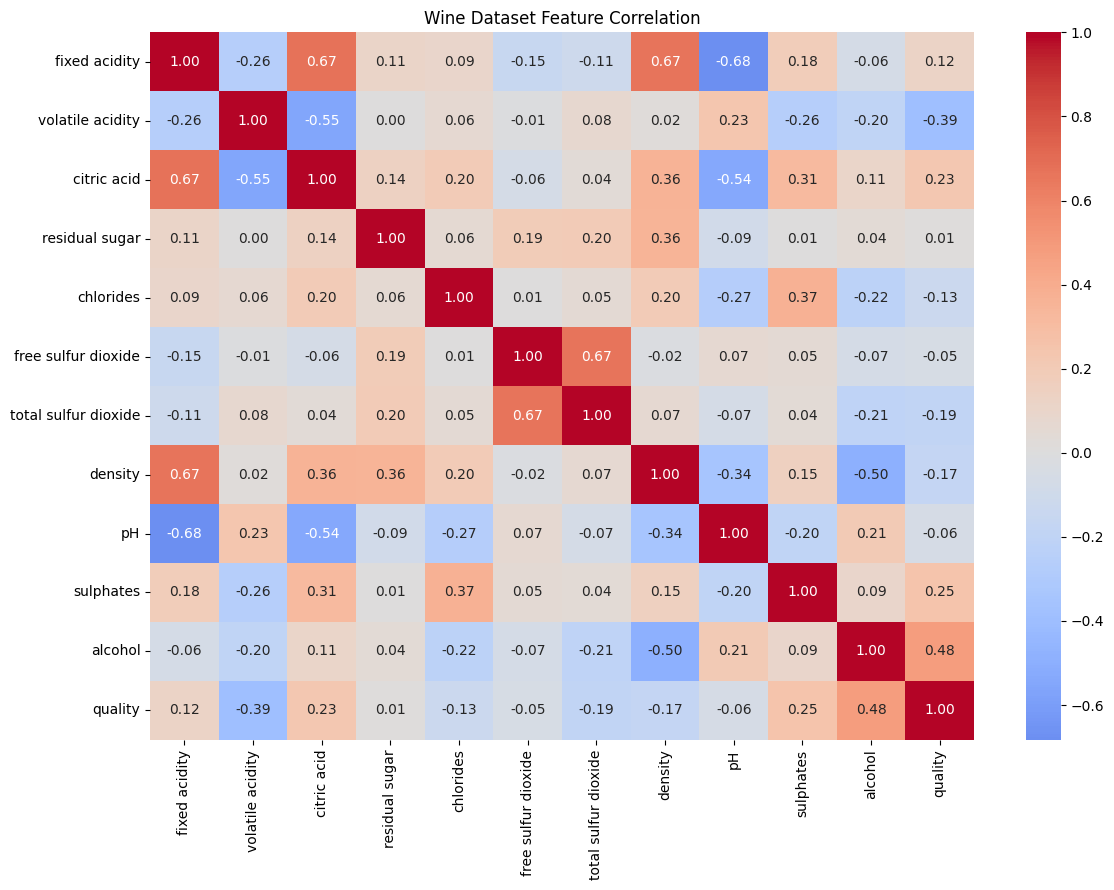

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


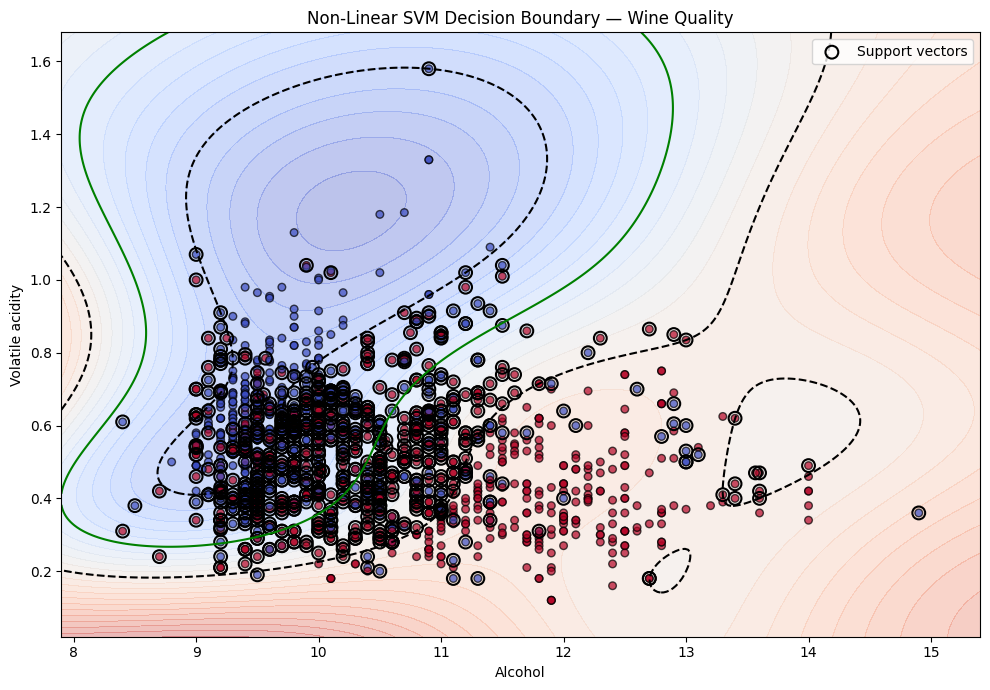

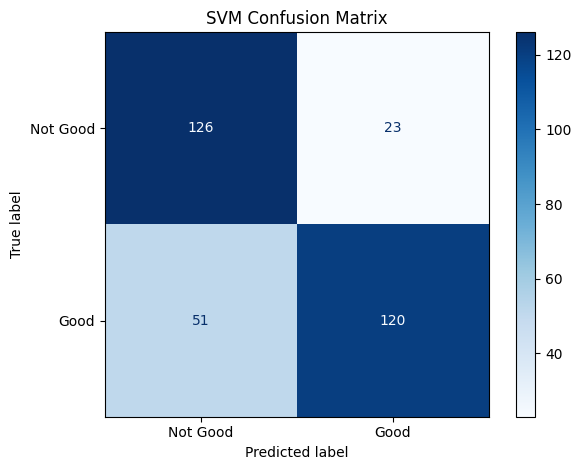

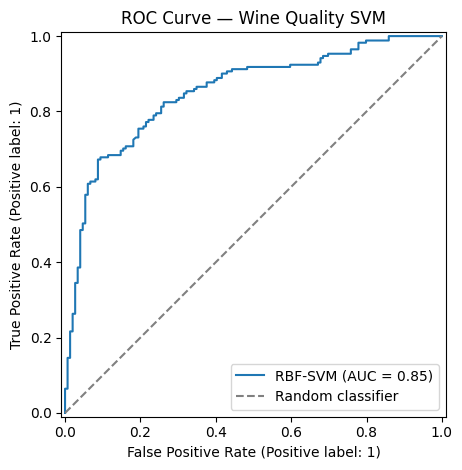

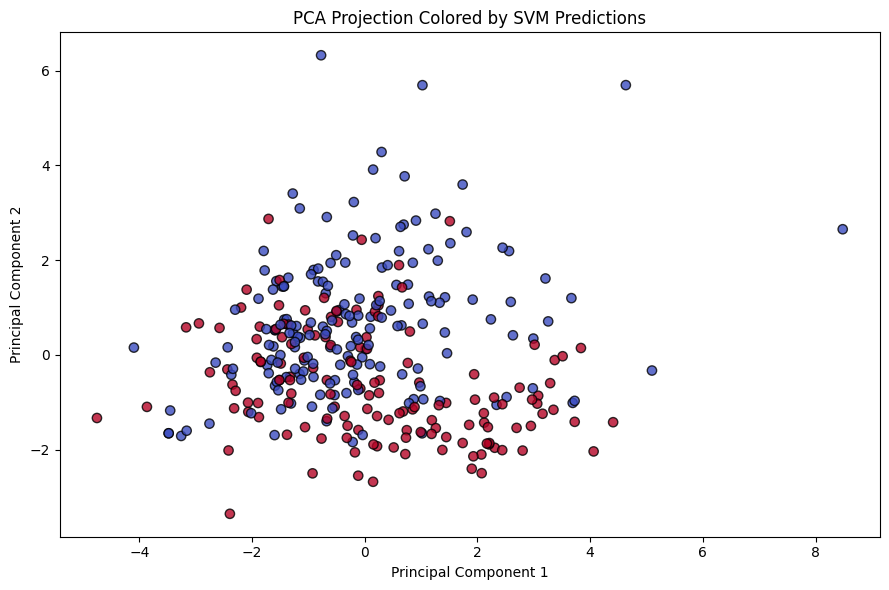


Sample Predictions:
     Actual Quality Predicted Quality
100            Good          Not Good
1391       Not Good          Not Good
170        Not Good          Not Good
461        Not Good          Not Good
346            Good              Good
1126           Good              Good
860        Not Good          Not Good
1363       Not Good          Not Good
776            Good              Good
1440           Good              Good
1256       Not Good          Not Good
1280           Good              Good
246        Not Good          Not Good
463        Not Good          Not Good
49         Not Good          Not Good

Total support vectors in full model: 720

Explained variance by PCA components: [0.2805 0.1706]


In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)



url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/winequality-red.csv"
)

df = pd.read_csv(url, sep=";")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nOriginal quality distribution:")
print(df["quality"].value_counts().sort_index())

# ------------------------------------------------------------
# 2. DATA PREPROCESSING
# ------------------------------------------------------------

# Binary classification:
# Quality >= 6 -> Good (1)
# Quality < 6  -> Not good (0)

X = df.drop(columns=["quality"])
y = (df["quality"] >= 6).astype(int)

print("\nBinary class distribution:")
print(y.value_counts().rename({
    0: "Not good",
    1: "Good"
}))

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 4. NON-LINEAR SVM WITH RBF KERNEL
# ------------------------------------------------------------

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

# Hyperparameter tuning
param_grid = {
    "svm__C": [0.1, 1, 10],
    "svm__gamma": ["scale", 0.01, 0.1]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("\nTraining SVM...")
grid.fit(X_train, y_train)

model = grid.best_estimator_

print("\nBest parameters:", grid.best_params_)

# ------------------------------------------------------------
# 5. MODEL EVALUATION
# ------------------------------------------------------------

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Good", "Good"]
))

# ------------------------------------------------------------
# 6. VISUAL 1: CLASS DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(
    x=y.map({0: "Not Good", 1: "Good"}),
    hue=y.map({0: "Not Good", 1: "Good"}),
    legend=False,
    palette="Set2"
)

plt.title("Wine Quality: Binary Class Distribution")
plt.xlabel("Wine quality class")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. VISUAL 2: CORRELATION HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Wine Dataset Feature Correlation")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. VISUAL 3: NON-LINEAR DECISION BOUNDARY
# Use two features for a genuine 2D SVM visualization
# ------------------------------------------------------------

features_2d = ["alcohol", "volatile acidity"]

X2 = X[features_2d]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

svm_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=grid.best_params_["svm__C"],
        gamma=grid.best_params_["svm__gamma"],
        class_weight="balanced"
    ))
])

svm_2d.fit(X2_train, y2_train)

# Grid for plotting decision regions
x_min, x_max = X2["alcohol"].min() - 0.5, X2["alcohol"].max() + 0.5
y_min, y_max = (
    X2["volatile acidity"].min() - 0.1,
    X2["volatile acidity"].max() + 0.1
)

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

decision_values = svm_2d.decision_function(
    grid_points
).reshape(xx.shape)

plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, decision_values,
    levels=30,
    cmap="coolwarm",
    alpha=0.35
)

# Decision boundary and margins
plt.contour(
    xx, yy, decision_values,
    levels=[-1, 0, 1],
    colors=["black", "green", "black"],
    linestyles=["--", "-", "--"]
)

# Plot training samples
plt.scatter(
    X2_train["alcohol"],
    X2_train["volatile acidity"],
    c=y2_train,
    cmap="coolwarm",
    edgecolors="black",
    s=30,
    alpha=0.7
)

# Highlight support vectors
scaler_2d = svm_2d.named_steps["scaler"]
svc_2d = svm_2d.named_steps["svm"]

support_vectors = scaler_2d.inverse_transform(
    svc_2d.support_vectors_
)

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=85,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support vectors"
)

plt.xlabel("Alcohol")
plt.ylabel("Volatile acidity")
plt.title("Non-Linear SVM Decision Boundary — Wine Quality")
plt.legend()
plt.tight_layout()
plt.show()


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Good", "Good"],
    cmap="Blues",
    values_format="d"
)

plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()



RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="RBF-SVM"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.title("ROC Curve — Wine Quality SVM")
plt.legend()
plt.tight_layout()
plt.show()



scaler_full = model.named_steps["scaler"]
svc_full = model.named_steps["svm"]

X_train_scaled = scaler_full.transform(X_train)
X_test_scaled = scaler_full.transform(X_test)

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_test_pca[:, 0],
    X_test_pca[:, 1],
    c=y_pred,
    cmap="coolwarm",
    s=45,
    edgecolors="black",
    alpha=0.8
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection Colored by SVM Predictions")
plt.tight_layout()
plt.show()



results = pd.DataFrame({
    "Actual Quality": y_test.map({
        0: "Not Good",
        1: "Good"
    }),
    "Predicted Quality": pd.Series(
        y_pred,
        index=y_test.index
    ).map({
        0: "Not Good",
        1: "Good"
    })
})

print("\nSample Predictions:")
print(results.head(15))

print("\nTotal support vectors in full model:",
      len(svc_full.support_vectors_))

print("\nExplained variance by PCA components:",
      np.round(pca.explained_variance_ratio_, 4))